__Tasks:__
- [x] Collect a MVD (Minimum Viable Data)
    - I'm using the raw data for MOLM-13 screen from this [bioRxiv](https://www.biorxiv.org/content/10.1101/2022.12.14.518457v1)
- [x] Trim reads in FASTQ, count unique sequences, and map to V2 sgRNA library table.
- [x] Compare with ScreenProcessing
- [ ] Test Command Line Interface (CLI) for the pipeline

___
    Thu Mar  7 03:55:05 UTC 2024

I have implmented all required features for single-guide and dual-guide designs. Here I want to perform enough tests to make sure I have everything ready to go for other users!

In [1]:
!pip uninstall -y screenpro2
!pip install git+https://github.com/arcinstitute/screenpro2.git@cli
# !pip install git+https://github.com/arcinstitute/screenpro2.git
# pip install screenpro2

Found existing installation: ScreenPro2 0.2.13
Uninstalling ScreenPro2-0.2.13:
  Successfully uninstalled ScreenPro2-0.2.13
  Cloning https://github.com/arcinstitute/screenpro2.git (to revision cli) to /tmp/pip-req-build-wxo4xajz
  Running command git clone --filter=blob:none --quiet https://github.com/arcinstitute/screenpro2.git /tmp/pip-req-build-wxo4xajz
  Running command git checkout -b cli --track origin/cli
  Switched to a new branch 'cli'
  branch 'cli' set up to track 'origin/cli'.
  Resolved https://github.com/arcinstitute/screenpro2.git to commit b0cebbac834723189ab6bfd93adf86b9026c9929
  Preparing metadata (setup.py) ... done
  Created wheel for ScreenPro2: filename=ScreenPro2-0.2.13-py3-none-any.whl size=28869 sha256=cf8c549d2d4fe4dd7b1bad163dded04679ccf647d5807719379659d3e582943f
  Stored in directory: /tmp/pip-ephem-wheel-cache-vuqs72j2/wheels/07/df/62/0c40d53ae17617e83ca0ebb6556a82eb7019e8e8c4f8c45a98
Successfully built ScreenPro2


In [2]:
import screenpro as scp

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import biobear as bb
import anndata as ad
import polars as pl
from time import time
from glob import glob

# from pyfaidx import Fasta

In [4]:
import numpy as np

In [5]:
def write_pkl(d, name):
    file_name = f'{name}.pkl'
    with open(file_name, 'wb') as file:
        pickle.dump(d, file)
        print(f'Object successfully saved to "{file_name}"')

def read_pkl(name):
    file_name = f'{name}.pkl'
    with open(file_name, 'rb') as f:
        d = pickle.load(f)
    return d

# Collect data
A Minimum Viable Data (MVD)!

In [6]:
import subprocess 

In [7]:
# %%bash 
# mkdir -p DDRi_PRDX1_screens_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v3/DDRi-PRDX1-screens/`; do
#     b=`basename $fq`;
#     echo $b;
#     gsutil cp $fq DDRi_PRDX1_screens_fastq/$b;
# done

In [8]:
# %%bash 
# mkdir -p molm13_exp_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v2/molm13_exp`; do
#     b=`basename $fq`;
#     gsutil cp $fq molm13_exp_fastq/$b;
# done

In [9]:
!screenpro counter --help

usage: screenpro counter [-h] [-c CAS_TYPE] [--single-guide-design]
                         [--dual-guide-design] -l LIBRARY [-s SAMPLE_SHEET]
                         [-o OUTPUT]

Process FASTQ files to count sgRNA sequences.

optional arguments:
  -h, --help            show this help message and exit
  -c CAS_TYPE, --cas-type CAS_TYPE
                        Type of Cas protein used for the screen. Default: cas9
  --single-guide-design
                        Single guide design library.
  --dual-guide-design   Dual guide design library.
  -l LIBRARY, --library LIBRARY
                        Path to library file.
  -s SAMPLE_SHEET, --sample_sheet SAMPLE_SHEET
                        Path to sample sheet.
  -o OUTPUT, --output OUTPUT
                        Path to output directory.


In [10]:
# !screenpro counter \
#     --single-guide-design \
#     -s 

## CRISPRi_v3

In [11]:
import os
from glob import glob
from screenpro.ngs import Counter

In [12]:
counter = Counter(cas_type = 'cas9', library_type = 'dual_guide_design')

In [13]:
counter.load_library('JR_V3lib_top2_v2.csv', sep = ',', verbose = True)

Trimming protospacer sequences in 'protospacer_B' column.
Library table successfully loaded.


In [14]:
samples = [
    os.path.basename(fq).split('_R1')[0] 
    for fq in glob('DDRi_PRDX1_screen/fastq/*R1.fastq.gz')
]
samples.sort()

In [15]:
help(counter.get_counts_matrix)

Help on method get_counts_matrix in module screenpro.ngs.counter:

get_counts_matrix(fastq_dir, samples, get_recombinant=False, cas_type='cas9', protospacer_length='auto', write=True, parallel=False, verbose=False) method of screenpro.ngs.counter.Counter instance
    Get count matrix for given samples



In [16]:
samples

['i01',
 'i02',
 'i03',
 'i04',
 'i05',
 'i06',
 'i07',
 'i08',
 'i09',
 'i10',
 'i11',
 'i12',
 'i13',
 'i14',
 'i15',
 'i16']

In [17]:
counter.get_counts_matrix(
    fastq_dir = 'DDRi_PRDX1_screen/fastq',
    samples = samples,
    get_recombinant=True,
    verbose = True
)

i01
count file exists ...
% mapped reads 67.22400750620561
% unmapped reads 33.726584213534
% fully remapped recombination events 26.590837206047766
i02
count file exists ...
% mapped reads 67.2224867068411
% unmapped reads 33.7441858631192
% fully remapped recombination events 26.600838850130977
i03
count file exists ...
% mapped reads 68.1109199726362
% unmapped reads 32.86033919818391
% fully remapped recombination events 25.383501001416466
i04
count file exists ...
% mapped reads 67.81789137852932
% unmapped reads 33.1477123357031
% fully remapped recombination events 25.4566485485245
i05
count file exists ...
% mapped reads 68.11778566537478
% unmapped reads 32.84939240634032
% fully remapped recombination events 25.425540590869016
i06
count file exists ...
% mapped reads 68.25794350916942
% unmapped reads 32.706146818395595
% fully remapped recombination events 25.510180589951293
i07
count file exists ...
% mapped reads 68.45407135065173
% unmapped reads 32.5235826625747
% fully 

In [ ]:
# library = library.rename(
#     columns={
#         'protospacer_A':'protospacer_a',
#         'protospacer_B':'protospacer_b'
#     })

In [18]:
# library = pd.read_csv(
#     'JR_V3lib_top2_v2.csv', index_col=0
#     # 'CRISPRi_dual_human_librarytable_corrected_v2.txt',
#     # sep='\t',low_memory=False
# ).rename(
#     columns={'protospacer_A':'protospacer_a','protospacer_B':'protospacer_b'}
# )

# # library['sequence'] = library.protospacer_a.str[1:] + ';' + library.protospacer_b.str[1:]
# # library.protospacer_a = library.protospacer_a.str[1:]


# library.protospacer_a = library.protospacer_a.str.upper()
# library.protospacer_b = library.protospacer_b.str[1:].str.upper()
# library['sequence'] = library.protospacer_a + ';' + library.protospacer_b

In [19]:
# library_top12 = library.query(
#     "predictedRank_A not in ['3','5'] & predictedRank_B not in ['4','6']"
# ).reset_index(drop=True)

In [20]:
# !gsutil ls gs://illumina-raw/MiSeq/

In [21]:
meta = pd.read_excel('DDRi_PRDX1_screen/PRDX1samplesheet_incgrowth.xlsx').set_index('index')

In [30]:
adata = counter.build_counts_anndata(source='library')
adata.obs = meta

In [31]:
adata.var['targetType'] = ''
adata.var.loc[adata.var.target.eq('negative_control'),'targetType']  = 'negCtrl'
adata.var.loc[~adata.var.target.eq('negative_control'),'targetType'] = 'gene'
adata.var.index.name = None

adata.obs.treatment = adata.obs.treatment.str.replace('-','T0')
adata.obs = adata.obs.rename(columns={'treatment':'condition','rep':'replicate'})

adata.obs['pop_doublings'] = meta['pop doublings'].replace('-',np.nan).astype(float)

del adata.obs['pop doublings']

In [32]:
adata.write_h5ad("DDRi_PRDX1_screen/adata.h5ad.gz",compression='gzip')

___

In [33]:
adata_old = ad.read_h5ad('DDRi_PRDX1_screen/old_adata_counts.h5ad.gz')

In [34]:
# adata_old.to_df().T[['i01']].index.str.split('++')

In [35]:
i01_screenpro2_count = adata.to_df().T[['i01']]

In [36]:
i01_old_count = adata_old.to_df().T[['i01']].rename(columns={'i01':'i01_old'})

i01_old_count.index = i01_old_count.index.str.split('\+\+').str[1]

In [37]:
i01_ol_df = pd.concat([
    i01_old_count,
    i01_screenpro2_count
    ]
,axis=1)

<AxesSubplot: xlabel='i01_old', ylabel='i01'>

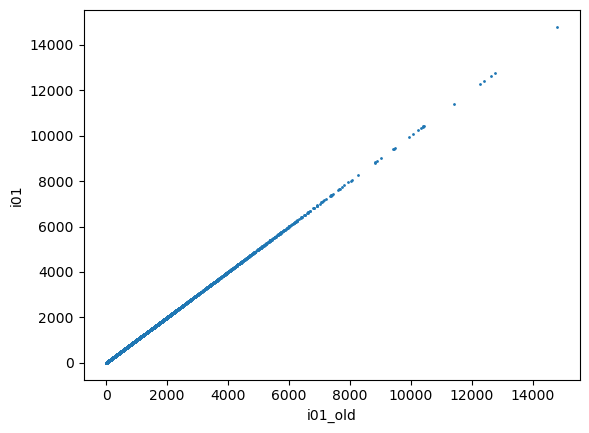

In [38]:
i01_ol_df.plot.scatter('i01_old','i01',s=1)

___

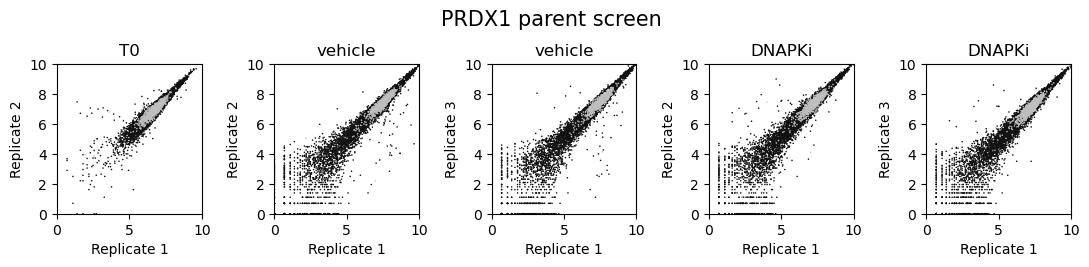

In [37]:
fig, axes = plt.subplots(ncols=5,
                         figsize=(13,3), 
                         gridspec_kw={'wspace': 0.5, 'left': 0.12,'top':.8,'bottom':.3}, 
                         # sharey=True
                        )
scp.pl.plotReplicateScatter(axes[0], adata, 'i01','i02','T0',min_val=0,max_val=10)
scp.pl.plotReplicateScatter(axes[1], adata, 'i03','i04','vehicle',min_val=0,max_val=10)
scp.pl.plotReplicateScatter(axes[2], adata, 'i03','i05','vehicle',min_val=0,max_val=10)
scp.pl.plotReplicateScatter(axes[3], adata, 'i06','i07','DNAPKi',min_val=0,max_val=10)
scp.pl.plotReplicateScatter(axes[4], adata, 'i06','i08','DNAPKi',min_val=0,max_val=10)

fig.suptitle('PRDX1 parent screen',fontsize=15)

# plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
plt.show()


___

In [39]:
import screenpro as scp

In [40]:
adata_PRDX1KO = adata[adata.obs['cell line'].eq('PRDX1KO')].copy()
adata_parent  = adata[adata.obs['cell line'].eq('parent')].copy()

In [41]:
screen0 = scp.PooledScreens(adata_parent)
screen = scp.PooledScreens(adata_parent[adata_parent.obs.replicate.isin([1,2])].copy(),n_reps=2)

In [42]:
screen.calculateDrugScreen(
    t0='T0', untreated='vehicle', treated='DNAPKi',
    db_untreated = 7.8,
    db_treated = 7.5,
    score_level='compare_reps'
)


	vehicle vs T0
	DNAPKi vs T0
	DNAPKi vs vehicle


In [45]:
screen.pdata

AnnData object with n_obs × n_vars = 6 × 21554
    obs: 'score', 'growth_factor', 'replicate'
    var: 'target', 'sgID_A', 'protospacer_A', 'sgID_B', 'protospacer_B', 'sequence', 'targetType'

/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scanpy/preprocessing/_simple.py:377: RuntimeWarning: invalid value encountered in log1p
  np.log1p(X, out=X)
/home/abearab/miniforge3/envs/screenpro2/lib/python3.9/site-packages/scanpy/preprocessing/_simple.py:377: RuntimeWarning: invalid value encountered in log1p
  np.log1p(X, out=X)


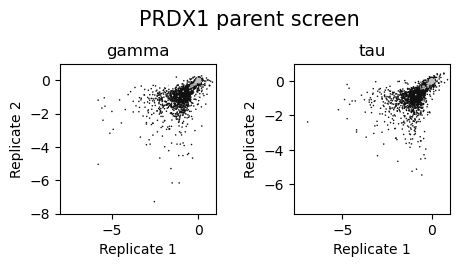

In [46]:
fig, axes = plt.subplots(ncols=2,
                         figsize=(5,3), 
                         gridspec_kw={'wspace': 0.5, 'left': 0.12,'top':.8,'bottom':.3}, 
                         # sharey=True
                        )
scp.pl.plotReplicateScatter(axes[0], screen.pdata, 'gamma_replicate_1','gamma_replicate_2','gamma',max_val=1)
scp.pl.plotReplicateScatter(axes[1], screen.pdata, 'tau_replicate_1','tau_replicate_2','tau',max_val=1)


fig.suptitle('PRDX1 parent screen',fontsize=15)

# plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
plt.show()

In [47]:
scp.utils.find_low_counts(screen0.adata)

44 variables with less than 50 reads in either replicates / experiment


In [48]:
sel = ['target','score','ttest pvalue']# BH adj_pvalue # ttest pvalue
gamma = screen.phenotypes['compare_reps']['gamma:vehicle_vs_T0'].loc[:,sel].reset_index(drop=True)

tau = screen.phenotypes['compare_reps']['tau:DNAPKi_vs_T0'].loc[:,sel].reset_index(drop=True)

rho = screen.phenotypes['compare_reps']['rho:DNAPKi_vs_vehicle'].loc[:,sel].reset_index(drop=True)

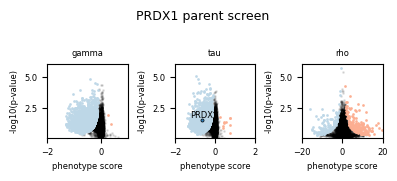

In [49]:
# Create subplots and specify the size
fig, (ax1,ax2,ax3) = plt.subplots(1,3,figsize=(4, 1.8))

scp.pl.plot_volcano(ax1, gamma,threshold=5,xlim_l=-2, xlim_r=1,ctrl_label='negative_control')
ax1.grid(False)
ax1.get_legend().remove()
ax1.set_title('gamma')

scp.pl.plot_volcano(ax2, tau,threshold=5,xlim_l=-2, xlim_r=2,ctrl_label='negative_control')
scp.pl.label_sensitivity_hit(ax2,tau,'PRDX1',threshold=5,size=5,size_txt=6,t_x=-.6,t_y=.2,ctrl_label='negative_control')

ax2.grid(False)
ax2.get_legend().remove()
ax2.set_title('tau')

scp.pl.plot_volcano(ax3, rho,threshold=5,xlim_l=-20, xlim_r=20,ctrl_label='negative_control')
# label_resistance_hit(ax2,rho,'TTC1',size=5,size_txt=6,t_x=.1)
# label_sensitivity_hit(ax2,rho,'CLHC1',size=5,size_txt=6,t_y=.1)

ax3.grid(False)
ax3.get_legend().remove()
ax3.set_title('rho')


for ax in [ax1,ax2,ax3]:
    for item in ([ax.title, ax.xaxis.label, ax.yaxis.label] + ax.get_xticklabels() + ax.get_yticklabels()):
        item.set_fontsize(6)

fig.suptitle('PRDX1 parent screen',fontsize=9)
plt.tight_layout()
# Show the plot
plt.show()

### 

## CRISPRi_v2

### Count FASTQ ...

In [11]:
samples = []
for fq_file in glob('molm13_exp_fastq/*.fastq.gz'):
    sample_id = fq_file.split('/')[1].replace('.fastq.gz','')
    # sample_id = fq_file.split('/')[1].split('.')[0].split('_S')[0]
    samples.append(sample_id)
samples

['DMSO_Rep2', 'DAC_Rep1', 'T0_Rep1', 'DAC_Rep2', 'DMSO_Rep1', 'T0_Rep2']

In [12]:
counter = scp.ngs.Counter(cas_type = 'cas9', library_type = 'single_guide_design')

In [13]:
CRISPRi_v2_human_path = '../../../ScreenPro2/library_tables/CRISPRi_v2_human_librarytable.txt.gz'

In [14]:
counter.load_library(CRISPRi_v2_human_path, sep = '\t', verbose = True, index_col=None, protospacer_length=20)

Library table successfully loaded.


In [15]:
counter.get_counts_matrix(
    fastq_dir = 'molm13_exp_fastq/',
    samples = samples,
    # write = 'force',
    verbose = True
)

DMSO_Rep2
count file exists ...


% mapped reads 92.58204641632388
DAC_Rep1
count file exists ...
% mapped reads 92.60955745994914
T0_Rep1
count file exists ...
% mapped reads 92.90695241187068
DAC_Rep2
count file exists ...
% mapped reads 92.45927925994773
DMSO_Rep1
count file exists ...
% mapped reads 92.50830112599218
T0_Rep2
count file exists ...
% mapped reads 92.83302899572263


In [16]:
adata = counter.build_counts_anndata()

### Compare counts with ScreenProcessing

In [17]:
# !wget 'https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/molm13_exp/mergedcountstable.txt'

In [18]:
screenprocessing_counts = pd.read_csv(
    'mergedcountstable.txt', 
    sep='\t', 
    header=list(range(2)),
    index_col=list(range(1))
)

screenprocessing_counts = screenprocessing_counts[screenprocessing_counts.sum(axis=1).gt(0)]

<AxesSubplot: >

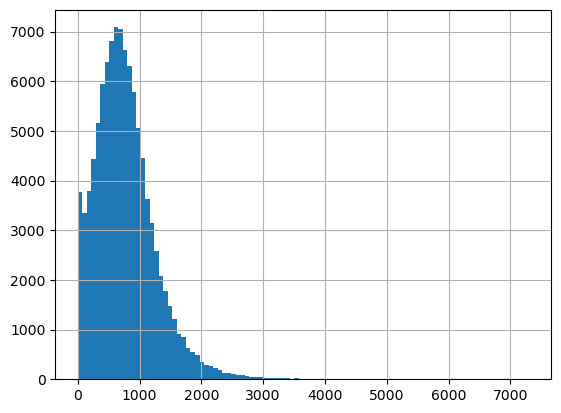

In [19]:
screenprocessing_counts['T0']['Rep1'].hist(bins=100)

Text(0.5, 1.0, 'SingleGuideDesign\nCRISPRi-V2')

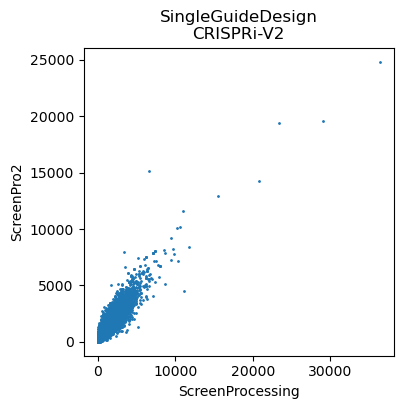

In [42]:
fig, ax = plt.subplots(figsize=(4,4))

pd.concat({
    'ScreenProcessing':screenprocessing_counts['DAC']['Rep2'], 
    'ScreenPro2':adata.to_df().loc['DMSO_Rep2',screenprocessing_counts.index]
},axis=1).plot.scatter('ScreenProcessing','ScreenPro2',s=1,ax=ax)

plt.title('SingleGuideDesign\nCRISPRi-V2')

In [43]:
def plot_count_benchmark():
    pass
    #screen, growth_factor_table, score, cond1, cond2, get_z_score, title):
#     screenprocessing_results = screen.phenotypes['phenotypetable'][score]

#     screenpro2_results = scp.ps.runPhenoScoreForReplicate(
#         screen,cond1,cond2,
#         score,
#         growth_factor_table,
#         get_z_score=get_z_score
#     ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

#     fig, ax = plt.subplots(figsize=(3.7,3.7))

#     ax.scatter(
#         x=screenprocessing_results['Rep1'],
#         y=screenpro2_results['replicate_1'],
#         facecolors='#3182bd',
#         s=3,c=almost_black
#     )
#     ax.set_xlabel('ScreenProcessing')
#     ax.set_ylabel('ScreenPro2\nscore')

#     ax.axline((0, 0), slope=1)

#     # ax.set_xlim(-3.5,3.5)
#     # ax.set_ylim(-3.5,3.5)

#     fig.suptitle(title,fontsize=12)

#     # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
#     # plt.tight_layout()
#     plt.show()

In [44]:
plot_count_benchmark()

# 

In [45]:
%load_ext watermark
%watermark
%watermark --iversions

Last updated: 2024-05-10T23:30:18.036568+00:00

Python implementation: CPython
Python version       : 3.9.18
IPython version      : 8.15.0

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 6.1.0-21-cloud-amd64
Machine     : x86_64
Processor   : 
CPU cores   : 16
Architecture: 64bit

anndata   : 0.10.7
numpy     : 1.26.0
polars    : 0.20.23
biobear   : 0.20.0
matplotlib: 3.6.2
pandas    : 1.5.3
screenpro : 0.2.13

